# **Xử lý và biểu diễn dữ lệu**

cell 1

In [1]:
import pandas as pd
import numpy as np
from datetime import datetime, timedelta

# Đọc dữ liệu CSV
data = pd.read_csv('/kaggle/input/300-seconds/machine_usage_days_1_to_8_grouped_300_seconds.csv')

# Tạo cột timestamp
start_time = datetime(2021, 1, 1, 0, 0, 0)
timestamps = [start_time + timedelta(seconds=300*i) for i in range(len(data))]
data['timestamp'] = timestamps

# --- CẢI TIẾN: Chỉ tạo lag/rolling cho các cột workload ---
workload_cols = ['net_in', 'net_out', 'disk_io_percent']
for col in workload_cols:
    for lag in [1, 3, 6, 12]:
        data[f'{col}_lag_{lag}'] = data[col].shift(lag)
    for window in [6, 12]:
        data[f'{col}_roll_mean_{window}'] = data[col].rolling(window=window).mean()

# Kỹ thuật đặc trưng tuần hoàn
data['hour'] = data['timestamp'].dt.hour
data['hour_sin'] = np.sin(2 * np.pi * data['hour']/23.0)
data['hour_cos'] = np.cos(2 * np.pi * data['hour']/23.0)
data['day_of_week'] = data['timestamp'].dt.weekday
data['day_sin'] = np.sin(2 * np.pi * data['day_of_week']/6.0)
data['day_cos'] = np.cos(2 * np.pi * data['day_of_week']/6.0)

# Đặc trưng xu hướng tuyến tính
data['time_idx'] = np.arange(len(data))

# Bỏ các hàng có giá trị NaN và các cột không cần nữa
data = data.dropna().reset_index(drop=True)
data = data.drop(['hour', 'day_of_week'], axis=1)

print("Đã tạo lag/rolling features chỉ cho workload.")
print("Dáng của dữ liệu mới:", data.shape)

# Phân chia tập train và test
train_size = 2016 - 12
train_data = data.iloc[:train_size].copy()
test_data  = data.iloc[train_size:].copy()

print("\nTotal data points after cleaning:", len(data))
print("Train period:", train_data['timestamp'].min(), "->", train_data['timestamp'].max())
print("Test period:", test_data['timestamp'].min(), "->", test_data['timestamp'].max())

Đã tạo lag/rolling features chỉ cho workload.
Dáng của dữ liệu mới: (2231, 29)

Total data points after cleaning: 2231
Train period: 2021-01-01 01:00:00 -> 2021-01-07 23:55:00
Test period: 2021-01-08 00:00:00 -> 2021-01-08 18:50:00


cell 2

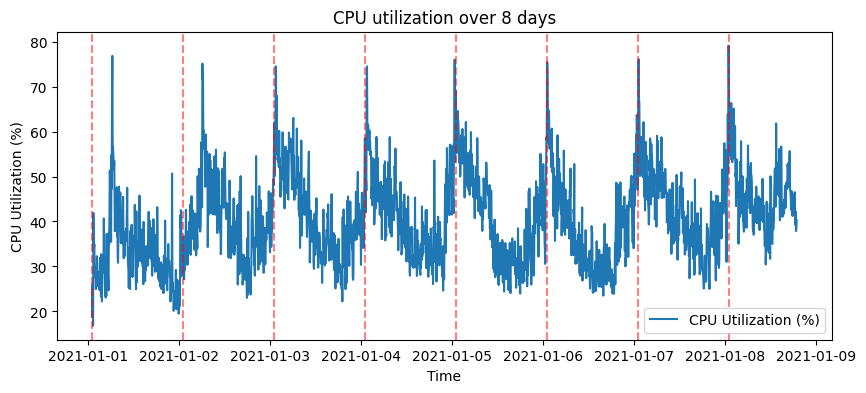

In [2]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,4))
plt.plot(data['timestamp'], data['cpu_util_percent'], label='CPU Utilization (%)')
# Vẽ đường dọc phân cách các ngày
for day_start in pd.date_range(start=data['timestamp'].min(), end=data['timestamp'].max(), freq='D'):
    plt.axvline(day_start, color='red', linestyle='--', alpha=0.5)
plt.title("CPU utilization over 8 days")
plt.xlabel("Time")
plt.ylabel("CPU Utilization (%)")
plt.legend()
plt.show()


cell 3

In [3]:
from sklearn.preprocessing import StandardScaler

# --- CẢI TIẾN: Scale riêng từng nhóm để bảo toàn thông tin ---
# Các cột workload và các đặc trưng phái sinh của chúng
workload_features_to_scale = [
    'net_in', 'net_out', 'disk_io_percent',
    'net_in_lag_1', 'net_in_lag_3', 'net_in_lag_6', 'net_in_lag_12',
    'net_in_roll_mean_6', 'net_in_roll_mean_12',
    'net_out_lag_1', 'net_out_lag_3', 'net_out_lag_6', 'net_out_lag_12',
    'net_out_roll_mean_6', 'net_out_roll_mean_12',
    'disk_io_percent_lag_1', 'disk_io_percent_lag_3', 'disk_io_percent_lag_6', 'disk_io_percent_lag_12',
    'disk_io_percent_roll_mean_6', 'disk_io_percent_roll_mean_12'
]
# Các đặc trưng không liên quan trực tiếp đến workload
other_features_to_scale = ['cpu_util_percent']
# Covariates
covariates_to_scale = ['time_idx', 'hour_sin', 'hour_cos', 'day_sin', 'day_cos']

# Khởi tạo scaler riêng
scaler_workload = StandardScaler()
scaler_other = StandardScaler()
scaler_covariates = StandardScaler()

# Fit và transform trên tập train
train_data[workload_features_to_scale] = scaler_workload.fit_transform(train_data[workload_features_to_scale])
train_data[other_features_to_scale] = scaler_other.fit_transform(train_data[other_features_to_scale])
train_data[covariates_to_scale] = scaler_covariates.fit_transform(train_data[covariates_to_scale])

# Chỉ transform trên tập test
test_data[workload_features_to_scale] = scaler_workload.transform(test_data[workload_features_to_scale])
test_data[other_features_to_scale] = scaler_other.transform(test_data[other_features_to_scale])
test_data[covariates_to_scale] = scaler_covariates.transform(test_data[covariates_to_scale])

print("Dữ liệu đã được chuẩn hóa với các scaler riêng cho từng nhóm đặc trưng.")

Dữ liệu đã được chuẩn hóa với các scaler riêng cho từng nhóm đặc trưng.


cell 4

In [4]:
import torch
import torch.nn as nn

# --- CẢI TIẾN: Chọn đúng cột cho mô hình ---
# Đầu vào X là các cột workload và lag/rolling của chúng
features_cols = workload_features_to_scale # Lấy từ cell 3
# Covariates vẫn như cũ
covariates_cols = covariates_to_scale
# Target là 3 cột workload gốc
target_workload_cols = ['net_in', 'net_out', 'disk_io_percent']

L = 288
H = 12

# Chuẩn bị dữ liệu huấn luyện
X_past_list, U_past_list, U_future_list, Y_future_list = [], [], [], []
train_features_vals = train_data[features_cols].values
train_covariates_vals = train_data[covariates_cols].values
train_targets_vals = train_data[target_workload_cols].values # Chỉ lấy 3 cột target

for i in range(L, len(train_data) - H + 1):
    past_x = train_features_vals[i-L : i]
    past_u = train_covariates_vals[i-L : i]
    future_u = train_covariates_vals[i : i+H]
    future_y = train_targets_vals[i : i+H] # Target là 3 cột workload gốc
    
    X_past_list.append(past_x)
    U_past_list.append(past_u)
    U_future_list.append(future_u)
    Y_future_list.append(future_y)

# Chuyển sang tensor PyTorch
X_past = torch.tensor(np.array(X_past_list), dtype=torch.float32)
U_past = torch.tensor(np.array(U_past_list), dtype=torch.float32)
U_future = torch.tensor(np.array(U_future_list), dtype=torch.float32)
Y_future = torch.tensor(np.array(Y_future_list), dtype=torch.float32)

print("Training samples shape (features):", X_past.shape)
print("Past covariates shape:", U_past.shape)
print("Future covariates shape:", U_future.shape)
print("Future target shape:", Y_future.shape)

Training samples shape (features): torch.Size([1705, 288, 21])
Past covariates shape: torch.Size([1705, 288, 5])
Future covariates shape: torch.Size([1705, 12, 5])
Future target shape: torch.Size([1705, 12, 3])


# **DAPM (Deep Attentive Periodic Model)**

cell 5

In [5]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class TrendBlock(nn.Module):
    def __init__(self, input_dim, output_dim, hidden_dim, num_layers=2):
        super(TrendBlock, self).__init__()
        layers = [nn.Linear(input_dim, hidden_dim), nn.GELU()]
        for _ in range(num_layers - 1):
            layers.extend([nn.Linear(hidden_dim, hidden_dim), nn.GELU()])
        layers.append(nn.Linear(hidden_dim, output_dim))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

class DAPMForecaster(nn.Module):
    def __init__(self, feature_dim, covariate_dim, hidden_dim, output_dim, horizon, n_heads=4, n_lstm_layers=2, dropout=0.2):
        super(DAPMForecaster, self).__init__()
        self.horizon = horizon
        self.hidden_dim = hidden_dim
        self.output_dim = output_dim
        self.feature_dim = feature_dim # Lưu lại để reshape

        self.season_feature_embed = nn.Linear(feature_dim + covariate_dim, hidden_dim)
        self.season_query_embed = nn.Linear(covariate_dim, hidden_dim)
        self.activation = nn.GELU()
        self.lstm_encoder = nn.LSTM(
            input_size=hidden_dim, 
            hidden_size=hidden_dim, 
            num_layers=n_lstm_layers,
            batch_first=True,
            dropout=dropout if n_lstm_layers > 1 else 0
        )
        self.attention = nn.MultiheadAttention(embed_dim=hidden_dim, num_heads=n_heads, batch_first=True, dropout=dropout)
        self.norm1 = nn.LayerNorm(hidden_dim)
        self.season_decoder = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim * 2),
            self.activation,
            nn.Dropout(dropout),
            nn.Linear(hidden_dim * 2, output_dim)
        )
        
        self.trend_encoder = nn.Sequential(
            nn.Linear(288 * feature_dim, hidden_dim), # L = 288
            self.activation
        )
        self.trend_decoder = TrendBlock(hidden_dim, horizon * output_dim, hidden_dim)

    def forward(self, past_x, past_u, future_u):
        # --- Lấy giá trị cuối cùng của chuỗi workload gốc để làm điểm neo ---
        # past_x chứa tất cả 21 features, ta cần 3 features workload gốc
        # Giả định 3 features đầu tiên là 'net_in', 'net_out', 'disk_io_percent'
        last_value = past_x[:, -1:, 0:self.output_dim] # Shape: (batch, 1, output_dim)

        # --- Xử lý Nhánh Mùa vụ ---
        past_input_season = torch.cat([past_x, past_u], dim=-1)
        past_embed_season = self.activation(self.season_feature_embed(past_input_season))
        encoder_outputs, _ = self.lstm_encoder(past_embed_season)
        query = self.activation(self.season_query_embed(future_u))
        attn_output, _ = self.attention(query, encoder_outputs, encoder_outputs)
        attn_output = self.norm1(query + attn_output)
        season_forecast = self.season_decoder(attn_output)

        # --- Xử lý Nhánh Xu hướng ---
        trend_input = past_x.reshape(past_x.shape[0], -1)
        trend_encoded = self.trend_encoder(trend_input)
        trend_forecast_flat = self.trend_decoder(trend_encoded)
        trend_forecast = trend_forecast_flat.reshape(-1, self.horizon, self.output_dim)

        # --- CẢI TIẾN LỚN NHẤT: Kết hợp kết quả với điểm neo ---
        final_forecast = last_value + season_forecast + trend_forecast
        
        return final_forecast

# --- Khởi tạo lại mô hình ---
features_cols = workload_features_to_scale
covariates_cols = covariates_to_scale
target_workload_cols = ['net_in', 'net_out', 'disk_io_percent']

feature_dim = len(features_cols)       
covariate_dim = len(covariates_cols)   
output_dim = len(target_workload_cols) 
hidden_dim = 128 # Giữ nguyên hidden_dim=128, đã cho kết quả tốt
H = 12 

model = DAPMForecaster(
    feature_dim=feature_dim, 
    covariate_dim=covariate_dim, 
    hidden_dim=hidden_dim,
    output_dim=output_dim,
    horizon=H,
    n_lstm_layers=2,
    dropout=0.15 # Giảm nhẹ dropout
)

print("Final Hybrid model with Residual Connection created successfully.")

Final Hybrid model with Residual Connection created successfully.


cell 6

In [6]:
from torch.utils.data import DataLoader, TensorDataset, random_split
from torch.optim.lr_scheduler import CosineAnnealingLR

# Tạo DataLoader
dataset = TensorDataset(X_past, U_past, U_future, Y_future)
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)

# Cấu hình huấn luyện
# --- THAY ĐỔI: Tăng nhẹ LR, giữ nguyên số epoch và patience ---
optimizer = torch.optim.Adam(model.parameters(), lr=2e-4, weight_decay=1e-5) 
criterion = nn.L1Loss() 
epochs = 300 
scheduler = CosineAnnealingLR(optimizer, T_max=epochs // 10, eta_min=1e-6) 

# Early Stopping
best_val_loss = float('inf')
patience_counter = 0
patience_limit = 30 # Tăng patience một chút

print("Starting training the FINAL model...")
for epoch in range(1, epochs + 1):
    model.train()
    epoch_train_loss = 0.0
    for Xb, Ub, Uf, Yb in train_loader:
        optimizer.zero_grad()
        # --- THAY ĐỔI: Target của loss function bây giờ là sự thay đổi ---
        last_values = Xb[:, -1:, [features_cols.index(c) for c in target_workload_cols]]
        y_residual = Yb - last_values # Target là sự thay đổi so với điểm cuối
        
        # --- Sửa đổi: Mô hình vẫn dự báo giá trị tuyệt đối ---
        # Chúng ta sẽ tính toán phần dư từ output của mô hình
        Y_pred_absolute = model(Xb, Ub, Uf)
        Y_pred_residual = Y_pred_absolute - last_values
        
        loss = criterion(Y_pred_residual, y_residual)
        # ----------------------------------------------------

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        epoch_train_loss += loss.item() * Xb.size(0)
    epoch_train_loss /= len(train_dataset)
    
    model.eval()
    epoch_val_loss = 0.0
    with torch.no_grad():
        for Xb, Ub, Uf, Yb in val_loader:
            last_values = Xb[:, -1:, [features_cols.index(c) for c in target_workload_cols]]
            y_residual = Yb - last_values
            
            Y_pred_absolute = model(Xb, Ub, Uf)
            Y_pred_residual = Y_pred_absolute - last_values
            
            loss = criterion(Y_pred_residual, y_residual)
            epoch_val_loss += loss.item() * Xb.size(0)
    epoch_val_loss /= len(val_dataset)
    
    scheduler.step()
    
    if epoch % 10 == 0:
        current_lr = optimizer.param_groups[0]['lr']
        print(f"Epoch {epoch}: Train MAE = {epoch_train_loss:.4f} | Val MAE = {epoch_val_loss:.4f} | LR = {current_lr:.6f}")

    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        patience_counter = 0
        torch.save(model.state_dict(), 'best_dapm_model.pth')
    else:
        patience_counter += 1
        if patience_counter >= patience_limit:
            print(f"Early stopping at epoch {epoch}")
            break

model.load_state_dict(torch.load('best_dapm_model.pth'))
print(f"Training finished. Best model loaded with Val MAE on residuals: {best_val_loss:.4f}")

Starting training the FINAL model...
Epoch 10: Train MAE = 0.2445 | Val MAE = 0.2377 | LR = 0.000150
Epoch 20: Train MAE = 0.2062 | Val MAE = 0.2296 | LR = 0.000051
Epoch 30: Train MAE = 0.1904 | Val MAE = 0.2268 | LR = 0.000001
Epoch 40: Train MAE = 0.1884 | Val MAE = 0.2271 | LR = 0.000051
Epoch 50: Train MAE = 0.1769 | Val MAE = 0.2264 | LR = 0.000150
Epoch 60: Train MAE = 0.1651 | Val MAE = 0.2238 | LR = 0.000200
Epoch 70: Train MAE = 0.1488 | Val MAE = 0.2233 | LR = 0.000150
Epoch 80: Train MAE = 0.1332 | Val MAE = 0.2144 | LR = 0.000051
Epoch 90: Train MAE = 0.1271 | Val MAE = 0.2140 | LR = 0.000001
Epoch 100: Train MAE = 0.1284 | Val MAE = 0.2144 | LR = 0.000051
Epoch 110: Train MAE = 0.1312 | Val MAE = 0.2169 | LR = 0.000150
Epoch 120: Train MAE = 0.1323 | Val MAE = 0.2185 | LR = 0.000200
Epoch 130: Train MAE = 0.1171 | Val MAE = 0.2177 | LR = 0.000150
Early stopping at epoch 134
Training finished. Best model loaded with Val MAE on residuals: 0.2135


cell 7 & cell 8

Focused DAPM Workload Forecast MAE (workload features): 0.60, RMSE: 1.32


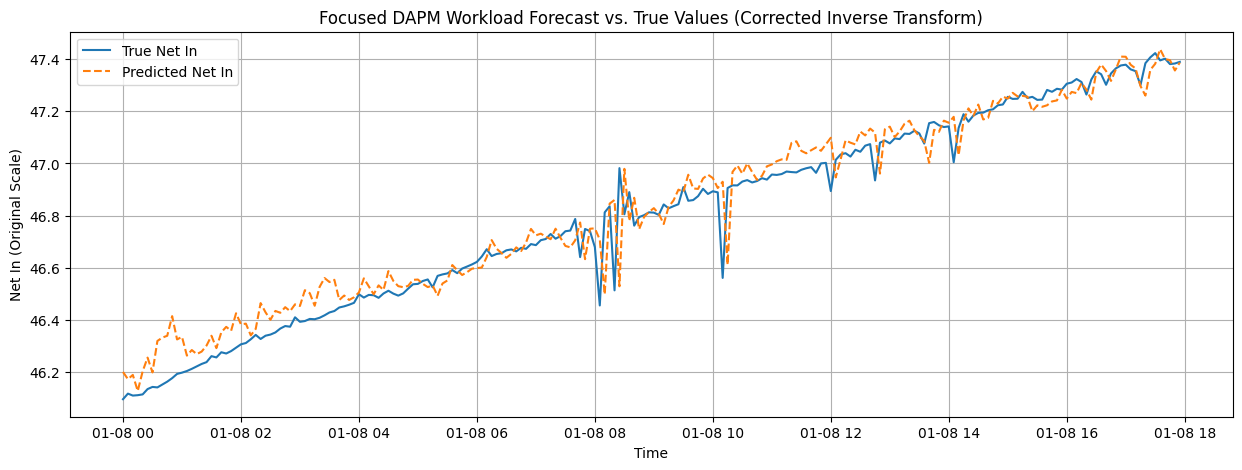

In [7]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt

model.eval()

# Lấy lại danh sách cột đã định nghĩa
features_cols = workload_features_to_scale
covariates_cols = covariates_to_scale
workload_cols = ['net_in', 'net_out', 'disk_io_percent']

L = 288
H = 12

# Nối lại dữ liệu train và test để dễ dàng lấy lịch sử
full_features_scaled = np.vstack((train_data[features_cols].values, test_data[features_cols].values))
full_covariates_scaled = np.vstack((train_data[covariates_cols].values, test_data[covariates_cols].values))

pred_list_scaled = []
true_list_scaled = []

start_of_test_idx = len(train_data)
# Tìm chỉ số của 3 cột workload trong danh sách features_cols đầy đủ
target_indices_in_features = [features_cols.index(c) for c in workload_cols]


with torch.no_grad():
    for i in range(start_of_test_idx, len(data) - H + 1):
        px = torch.tensor(full_features_scaled[i-L:i][None, ...], dtype=torch.float32)
        pu = torch.tensor(full_covariates_scaled[i-L:i][None, ...], dtype=torch.float32)
        fu = torch.tensor(full_covariates_scaled[i:i+H][None, ...], dtype=torch.float32)
        
        py_scaled = model(px, pu, fu).cpu().numpy().squeeze(0)
        
        # Lấy giá trị thực tế đã được scale của 3 cột target
        true_scaled = full_features_scaled[i:i+H][:, target_indices_in_features]
        
        pred_list_scaled.append(py_scaled[0])
        true_list_scaled.append(true_scaled[0])

pred_array_scaled = np.array(pred_list_scaled)
true_array_scaled = np.array(true_list_scaled)

if pred_array_scaled.shape[0] > 0:
    # --- SỬA LỖI QUAN TRỌNG: Dùng scaler_workload để inverse_transform ---
    # scaler_workload đã được fit trên 21 cột, nên nó không thể transform mảng 3 cột.
    # Chúng ta phải tạo một scaler MỚI CHỈ DÀNH CHO 3 CỘT WORKLOAD.
    
    # 1. Khởi tạo một scaler mới
    scaler_for_inverse = StandardScaler()
    
    # 2. Fit nó CHỈ trên 3 cột workload của dữ liệu train GỐC (chưa scale)
    # Để làm điều này, chúng ta cần đọc lại dữ liệu gốc hoặc dùng một mẹo nhỏ
    # Vì scaler_workload đã được fit, chúng ta có thể trích xuất mean và scale của 3 cột đầu tiên
    mean_workload = scaler_workload.mean_[0:3]
    scale_workload = scaler_workload.scale_[0:3]
    
    scaler_for_inverse.mean_ = mean_workload
    scaler_for_inverse.scale_ = scale_workload
    
    # 3. Bây giờ inverse_transform sẽ hoạt động
    pred_array = scaler_for_inverse.inverse_transform(pred_array_scaled)
    true_array = scaler_for_inverse.inverse_transform(true_array_scaled)

    mae = mean_absolute_error(true_array, pred_array)
    rmse = np.sqrt(mean_squared_error(true_array, pred_array))
    print(f"Focused DAPM Workload Forecast MAE (workload features): {mae:.2f}, RMSE: {rmse:.2f}")

    # Trực quan hóa cho 'net_in'
    plt.figure(figsize=(15, 5))
    start_of_test_in_original_data = data[data['timestamp'] == test_data['timestamp'].iloc[0]].index[0]
    time_axis = data['timestamp'].iloc[start_of_test_in_original_data : start_of_test_in_original_data + len(true_array)]
    
    plt.plot(time_axis, true_array[:, 0], label='True Net In')
    plt.plot(time_axis, pred_array[:, 0], label='Predicted Net In', linestyle='--')
    
    plt.title('Focused DAPM Workload Forecast vs. True Values (Corrected Inverse Transform)')
    plt.xlabel('Time')
    plt.ylabel('Net In (Original Scale)')
    plt.legend()
    plt.grid(True)
    plt.show()
else:
    print("Không có đủ dữ liệu trong tập test để tạo mẫu đánh giá.")

# **ANP (Attentive Neural Process)**

cell 9

In [8]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader, random_split
from torch.optim.lr_scheduler import ReduceLROnPlateau

# --- Sử dụng kiến trúc ANP mạnh nhất của bạn để làm một Forecaster chuyên dụng ---
# Đổi tên class để rõ ràng hơn về chức năng
class CPUForecaster(nn.Module):
    def __init__(self, x_dim, cov_dim, y_dim, hidden_dim, horizon, num_heads=8, n_lstm_layers=2, dropout=0.2):
        super(CPUForecaster, self).__init__()
        self.horizon = horizon
        
        # Encoder để học biểu diễn từ chuỗi lịch sử
        self.encoder_embedding = nn.Linear(x_dim + cov_dim, hidden_dim)
        self.lstm_encoder = nn.LSTM(
            input_size=hidden_dim, hidden_size=hidden_dim, 
            num_layers=n_lstm_layers, batch_first=True,
            dropout=dropout
        )
        
        # Query encoder cho các bước thời gian trong tương lai
        self.query_encoder = nn.Linear(cov_dim, hidden_dim)

        self.attention = nn.MultiheadAttention(embed_dim=hidden_dim, num_heads=num_heads, batch_first=True)
        self.norm = nn.LayerNorm(hidden_dim)
        
        # Decoder để dự đoán giá trị CPU
        self.decoder = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim * 2), nn.ReLU(),
            nn.Linear(hidden_dim * 2, y_dim)
        )

    def forward(self, past_x, past_cov, future_cov):
        # Lấy giá trị CPU cuối cùng trong lịch sử làm điểm neo
        cpu_col_index = past_x.shape[-1] - 1
        last_value = past_x[:, -1:, [cpu_col_index]]

        # Mã hóa chuỗi lịch sử
        past_input = torch.cat([past_x, past_cov], dim=-1)
        past_embed = F.relu(self.encoder_embedding(past_input))
        lstm_out, _ = self.lstm_encoder(past_embed)

        # Tạo query cho các bước thời gian tương lai
        query = self.query_encoder(future_cov)
        
        # Attention
        attn_out, _ = self.attention(query, lstm_out, lstm_out)
        
        # Dự đoán phần dư (delta)
        pred_delta = self.decoder(self.norm(attn_out))
        
        # Cộng phần dư vào điểm neo
        return last_value + pred_delta

# --- Chuẩn bị dữ liệu ---
# Input X: Tất cả các đặc trưng (workload gốc, lag/roll, cpu)
# Input U: Các đặc trưng thời gian (covariates)
# Target Y: CPU
features_cols_cpu = workload_features_to_scale + other_features_to_scale # 22 features
covariates_cols_cpu = covariates_to_scale # 5 features
target_col_cpu = ['cpu_util_percent']

L, H = 288, 12

# Tạo cửa sổ trượt
X_past_list, U_past_list, U_future_list, Y_future_list = [], [], [], []
train_features_vals = train_data[features_cols_cpu].values
train_cov_vals = train_data[covariates_cols_cpu].values
train_target_vals = train_data[target_col_cpu].values

for i in range(L, len(train_data) - H + 1):
    X_past_list.append(train_features_vals[i-L:i])
    U_past_list.append(train_cov_vals[i-L:i])
    U_future_list.append(train_cov_vals[i:i+H])
    Y_future_list.append(train_target_vals[i:i+H])

X_past_t, U_past_t, U_future_t, Y_future_t = [torch.tensor(np.array(d), dtype=torch.float32) for d in [X_past_list, U_past_list, U_future_list, Y_future_list]]

# --- Huấn luyện ---
cpu_forecaster_model = CPUForecaster(
    x_dim=len(features_cols_cpu), cov_dim=len(covariates_cols_cpu), y_dim=1, 
    hidden_dim=128, horizon=H
)

dataset = TensorDataset(X_past_t, U_past_t, U_future_t, Y_future_t)
train_size = int(0.85 * len(dataset))
val_size = len(dataset) - train_size
train_dataset, val_dataset = random_split(dataset, [train_size, val_size])

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)

optimizer = torch.optim.AdamW(cpu_forecaster_model.parameters(), lr=5e-4)
criterion = nn.L1Loss() # MAE loss
epochs = 150
scheduler = ReduceLROnPlateau(optimizer, 'min', patience=5, factor=0.5, verbose=True)

best_val_loss = float('inf')
patience_counter = 0
patience_limit = 20

print("\nStarting CPU Forecaster training...")
for epoch in range(1, epochs + 1):
    cpu_forecaster_model.train()
    for xb, ub_past, ub_future, yb in train_loader:
        optimizer.zero_grad()
        pred_y = cpu_forecaster_model(xb, ub_past, ub_future)
        loss = criterion(pred_y, yb)
        loss.backward()
        optimizer.step()
    
    cpu_forecaster_model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for xb, ub_past, ub_future, yb in val_loader:
            pred_y = cpu_forecaster_model(xb, ub_past, ub_future)
            val_loss += criterion(pred_y, yb).item()
    val_loss /= len(val_loader)
    
    scheduler.step(val_loss)
    print(f"Epoch {epoch}: Val MAE = {val_loss:.4f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(cpu_forecaster_model.state_dict(), 'best_cpu_forecaster.pth')
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= patience_limit:
            print(f"Early stopping at epoch {epoch}")
            break

cpu_forecaster_model.load_state_dict(torch.load('best_cpu_forecaster.pth'))
print(f"CPU Forecaster training finished. Best Val MAE: {best_val_loss:.4f}")

/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(



Starting CPU Forecaster training...
Epoch 1: Val MAE = 0.5966
Epoch 2: Val MAE = 0.5895
Epoch 3: Val MAE = 0.5876
Epoch 4: Val MAE = 0.5886
Epoch 5: Val MAE = 0.5890
Epoch 6: Val MAE = 0.5928
Epoch 7: Val MAE = 0.5878
Epoch 8: Val MAE = 0.5875
Epoch 9: Val MAE = 0.5953
Epoch 10: Val MAE = 0.5866
Epoch 11: Val MAE = 0.5849
Epoch 12: Val MAE = 0.5879
Epoch 13: Val MAE = 0.5833
Epoch 14: Val MAE = 0.5906
Epoch 15: Val MAE = 0.5816
Epoch 16: Val MAE = 0.5878
Epoch 17: Val MAE = 0.5864
Epoch 18: Val MAE = 0.5808
Epoch 19: Val MAE = 0.5787
Epoch 20: Val MAE = 0.5810
Epoch 21: Val MAE = 0.5842
Epoch 22: Val MAE = 0.5782
Epoch 23: Val MAE = 0.5788
Epoch 24: Val MAE = 0.5827
Epoch 25: Val MAE = 0.5833
Epoch 26: Val MAE = 0.5810
Epoch 27: Val MAE = 0.5795
Epoch 28: Val MAE = 0.5737
Epoch 29: Val MAE = 0.5735
Epoch 30: Val MAE = 0.5750
Epoch 31: Val MAE = 0.5765
Epoch 32: Val MAE = 0.5797
Epoch 33: Val MAE = 0.5766
Epoch 34: Val MAE = 0.5714
Epoch 35: Val MAE = 0.5759
Epoch 36: Val MAE = 0.5721


cell 10

In [9]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt

# --- Đánh giá CPU Forecaster trên tập test ---
cpu_forecaster_model.eval()
full_data = pd.concat([train_data, test_data], ignore_index=True)
pred_list, true_list = [], []

with torch.no_grad():
    for i in range(len(train_data), len(full_data) - H):
        past_x_input = torch.tensor(full_data[features_cols_cpu].iloc[i-L:i].values, dtype=torch.float32).unsqueeze(0)
        past_cov_input = torch.tensor(full_data[covariates_cols_cpu].iloc[i-L:i].values, dtype=torch.float32).unsqueeze(0)
        future_cov_input = torch.tensor(full_data[covariates_cols_cpu].iloc[i:i+H].values, dtype=torch.float32).unsqueeze(0)

        pred_y_scaled = cpu_forecaster_model(past_x_input, past_cov_input, future_cov_input).cpu().numpy().squeeze()
        true_y_scaled = full_data[target_col_cpu].iloc[i].values[0] # Lấy giá trị thực tế tại bước đầu tiên của horizon
        
        pred_list.append(pred_y_scaled[0])
        true_list.append(true_y_scaled)

# Inverse transform để đánh giá
pred_array_orig = scaler_other.inverse_transform(np.array(pred_list).reshape(-1, 1))
true_array_orig = scaler_other.inverse_transform(np.array(true_list).reshape(-1, 1))



Final CPU Forecaster MAE: 4.74, RMSE: 6.27


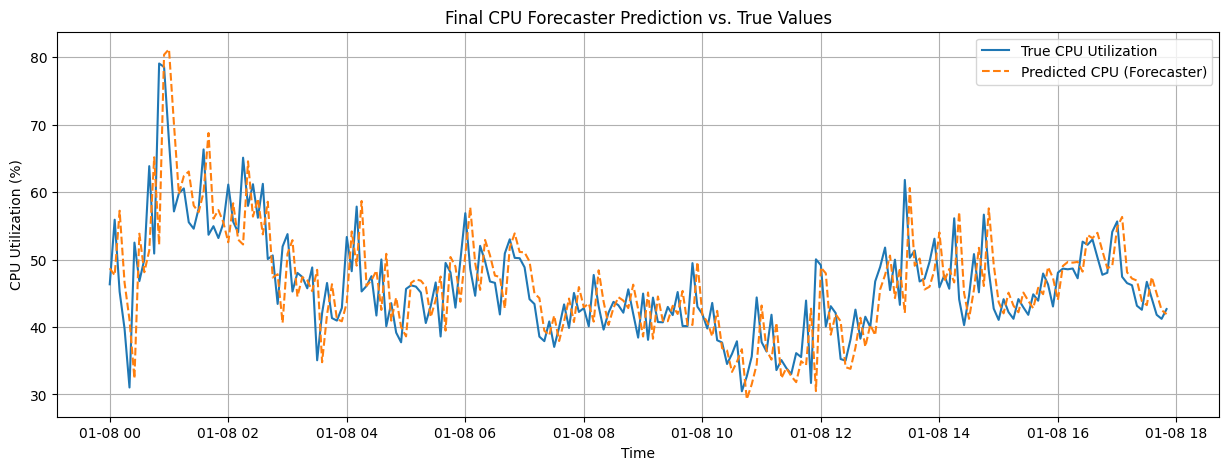

In [10]:
# Tính lỗi
mae_cpu = mean_absolute_error(true_array_orig, pred_array_orig)
rmse_cpu = np.sqrt(mean_squared_error(true_array_orig, pred_array_orig))
print(f"Final CPU Forecaster MAE: {mae_cpu:.2f}, RMSE: {rmse_cpu:.2f}")

# Trực quan hóa
plt.figure(figsize=(15, 5))
time_axis = test_data['timestamp'].iloc[:len(true_array_orig)]
plt.plot(time_axis, true_array_orig, label='True CPU Utilization')
plt.plot(time_axis, pred_array_orig, label='Predicted CPU (Forecaster)', linestyle='--')
plt.title('Final CPU Forecaster Prediction vs. True Values')
plt.xlabel('Time')
plt.ylabel('CPU Utilization (%)')
plt.legend()
plt.grid(True)
plt.show()

# **RL (Reinforcement Learning)**

cell 13

In [11]:
import torch
import torch.nn as nn
import collections
import torch.distributions as distributions

# --- 1. Định nghĩa mạng chính sách (Policy Network) ---
class PolicyNet(nn.Module):
    def __init__(self, state_dim, hidden_dim=64):
        super(PolicyNet, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(state_dim, hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, 1), nn.Tanh()
        )
    def forward(self, state):
        return 0.5 * self.net(state)

# --- 2. Khởi tạo các thành phần cho RL ---
# Lấy các mô hình đã được huấn luyện thành công ở các bước trước
workload_forecaster = model
cpu_forecaster = cpu_forecaster_model
workload_forecaster.eval()
cpu_forecaster.eval()

# State: 3 workload_dự_báo + 1 CPU_dự_báo + 1 VM_hiện_tại = 5
state_dim = 3 + 1 + 1 
policy_net = PolicyNet(state_dim)
opt_policy = torch.optim.Adam(policy_net.parameters(), lr=1e-4)

# Chuẩn hóa target_cpu về thang đo đã scale
target_cpu_orig = 50.0
target_cpu_scaled = scaler_other.transform(np.array([[target_cpu_orig]]))[0, 0]

# Các hằng số
lambda_cost = 0.1
gamma = 0.99
L, H = 288, 12

# Các cột cần thiết
dapm_features_cols = workload_features_to_scale
cpu_features_cols = workload_features_to_scale + other_features_to_scale
covariates_cols = covariates_to_scale

print("RL Policy Network and constants initialized correctly.")
print(f"State dimension for PolicyNet is: {state_dim}")

RL Policy Network and constants initialized correctly.
State dimension for PolicyNet is: 5


/usr/local/lib/python3.11/dist-packages/sklearn/base.py:439: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


cell 14

In [12]:
# --- Huấn luyện Policy bằng REINFORCE với hàm reward được cải tiến ---
gamma = 0.99
rl_episodes = 500
max_steps_per_episode = 100
all_rewards = []
full_data = pd.concat([train_data, test_data], ignore_index=True)

# --- THAY ĐỔI: Thêm hệ số phạt cho số lượng VM ---
target_cpu_orig = 50.0
target_cpu_scaled = scaler_other.transform(np.array([[target_cpu_orig]]))[0, 0]
lambda_cost_delta = 0.1 # Phạt vì thay đổi VM
lambda_cost_count = 0.05 # Phạt vì số lượng VM nhiều

# Các cột cần thiết
dapm_features_cols = workload_features_to_scale
cpu_features_cols = workload_features_to_scale + other_features_to_scale
covariates_cols = covariates_to_scale

print("\nStarting Final RL training with improved reward function...")
for i_episode in range(rl_episodes):
    day_idx = np.random.randint(2, 6) 
    start_t = day_idx * 288
    
    current_vms = 1.0
    saved_log_probs = []
    rewards = []

    for t in range(max_steps_per_episode):
        current_t = start_t + t
        if current_t + H >= len(train_data): break

        with torch.no_grad():
            past_x_dapm = torch.tensor(full_data[dapm_features_cols].iloc[current_t-L:current_t].values, dtype=torch.float32).unsqueeze(0)
            past_x_cpu = torch.tensor(full_data[cpu_features_cols].iloc[current_t-L:current_t].values, dtype=torch.float32).unsqueeze(0)
            past_cov = torch.tensor(full_data[covariates_cols].iloc[current_t-L:current_t].values, dtype=torch.float32).unsqueeze(0)
            future_cov = torch.tensor(full_data[covariates_cols].iloc[current_t:current_t+H].values, dtype=torch.float32).unsqueeze(0)

            pred_workloads_scaled = workload_forecaster(past_x_dapm, past_cov, future_cov).squeeze(0)
            pred_cpu_scaled = cpu_forecaster(past_x_cpu, past_cov, future_cov).squeeze(0)
        
        w_next_scaled = pred_workloads_scaled[0]
        cpu_next_scaled = pred_cpu_scaled[0]
        
        state = torch.cat([w_next_scaled, cpu_next_scaled, torch.tensor([current_vms], dtype=torch.float32)])
        
        action_tensor = policy_net(state)
        dist = distributions.Normal(action_tensor, torch.tensor([0.1])) 
        action = dist.sample()
        saved_log_probs.append(dist.log_prob(action))
        action_item = action.item()
        
        delta_vms = current_vms * action_item
        new_vms = current_vms + delta_vms
        if new_vms < 0.1: new_vms = 0.1

        controlled_cpu_scaled = cpu_next_scaled.item() * (current_vms / new_vms)
        
        # --- THAY ĐỔI: Thêm thành phần phạt số lượng VM ---
        reward_cpu = -((controlled_cpu_scaled - target_cpu_scaled)**2)
        cost_delta = lambda_cost_delta * (delta_vms**2)
        cost_count = lambda_cost_count * current_vms # Phạt số VM ở trạng thái hiện tại
        reward = reward_cpu - cost_delta - cost_count
        
        rewards.append(reward)
        current_vms = new_vms

    # Cập nhật Policy
    R = 0
    policy_loss = []
    returns = collections.deque()
    for r in rewards[::-1]:
        R = r + gamma * R
        returns.appendleft(R)
    returns = torch.tensor(list(returns), dtype=torch.float32)
    if len(returns) > 1:
        returns = (returns - returns.mean()) / (returns.std() + 1e-8)

    for log_prob, R in zip(saved_log_probs, returns):
        policy_loss.append(-log_prob * R)

    opt_policy.zero_grad()
    if policy_loss:
        policy_loss_tensor = torch.cat(policy_loss).sum()
        policy_loss_tensor.backward()
        opt_policy.step()

    all_rewards.append(sum(rewards))
    if (i_episode + 1) % 50 == 0:
        print(f'Episode {i_episode+1}/{rl_episodes}, Last 50 episodes avg reward: {np.mean(all_rewards[-50:]):.2f}')

torch.save(policy_net.state_dict(), 'best_policy_net.pth')
print("RL training finished.")

/usr/local/lib/python3.11/dist-packages/sklearn/base.py:439: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(



Starting Final RL training with improved reward function...
Episode 50/500, Last 50 episodes avg reward: -104.71
Episode 100/500, Last 50 episodes avg reward: -98.78
Episode 150/500, Last 50 episodes avg reward: -92.40
Episode 200/500, Last 50 episodes avg reward: -89.80
Episode 250/500, Last 50 episodes avg reward: -97.13
Episode 300/500, Last 50 episodes avg reward: -92.89
Episode 350/500, Last 50 episodes avg reward: -92.44
Episode 400/500, Last 50 episodes avg reward: -94.71
Episode 450/500, Last 50 episodes avg reward: -102.64
Episode 500/500, Last 50 episodes avg reward: -82.40
RL training finished.


# **Test hệ thống**

cell 15


Starting final system test...

--- System Test Results ---
CPU Stability (within ±5.0% of 50.0%): 40.9%
Average number of VMs: 0.54


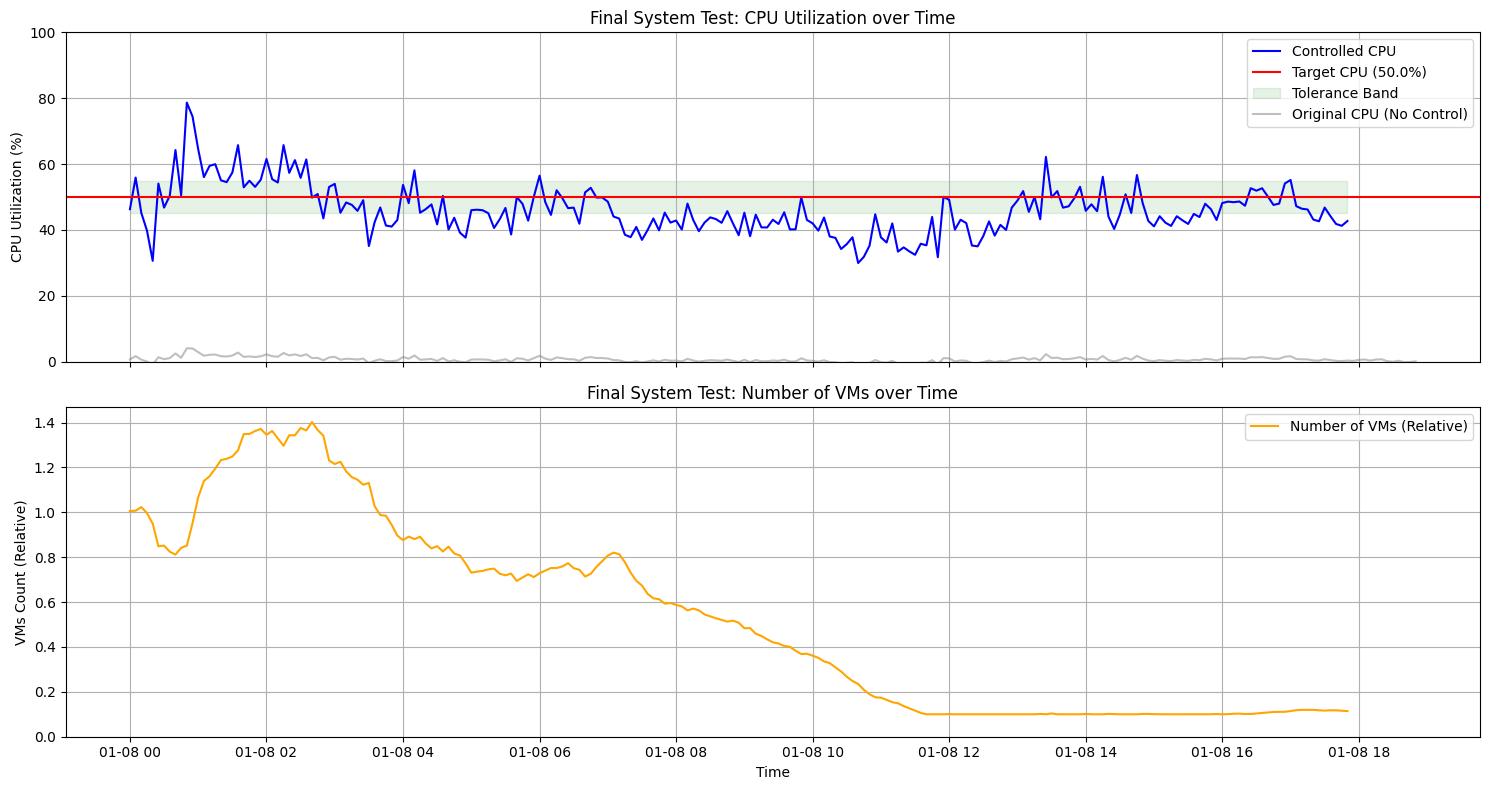

In [13]:
# --- Đánh giá toàn bộ hệ thống trên ngày test ---
policy_net.load_state_dict(torch.load('best_policy_net.pth'))
policy_net.eval()

target_cpu_orig = 50.0
tolerance = 5.0

# Trạng thái ban đầu
current_vms = 1.0
test_start_idx = len(train_data)
cpu_history_scaled, vms_history = [], []

print("\nStarting final system test...")
for t in range(test_start_idx, len(full_data) - H):
    # --- Dự báo state cho policy ---
    with torch.no_grad():
        past_x_dapm = torch.tensor(full_data[dapm_features_cols].iloc[t-L:t].values, dtype=torch.float32).unsqueeze(0)
        past_x_cpu = torch.tensor(full_data[cpu_features_cols].iloc[t-L:t].values, dtype=torch.float32).unsqueeze(0)
        past_cov = torch.tensor(full_data[covariates_cols].iloc[t-L:t].values, dtype=torch.float32).unsqueeze(0)
        future_cov = torch.tensor(full_data[covariates_cols].iloc[t:t+H].values, dtype=torch.float32).unsqueeze(0)

        pred_workload_scaled = workload_forecaster(past_x_dapm, past_cov, future_cov).squeeze(0)[0]
        pred_cpu_scaled = cpu_forecaster(past_x_cpu, past_cov, future_cov).squeeze(0)[0]

    # --- Tạo State và ra quyết định ---
    state = torch.cat([pred_workload_scaled, pred_cpu_scaled, torch.tensor([current_vms], dtype=torch.float32)])
    with torch.no_grad():
        action = policy_net(state).item()
        
    # --- Cập nhật và Mô phỏng ---
    new_vms = current_vms * (1 + action)
    if new_vms < 0.1: new_vms = 0.1
    
    # Lấy CPU thực tế xảy ra tại thời điểm t
    actual_cpu_scaled = full_data['cpu_util_percent'].iloc[t]
    # Mô phỏng CPU đã được kiểm soát 
    controlled_cpu_scaled = actual_cpu_scaled * (current_vms / new_vms)
    
    cpu_history_scaled.append(controlled_cpu_scaled)
    vms_history.append(new_vms)
    current_vms = new_vms

# --- Tính toán và Trực quan hóa kết quả ---
cpu_history_orig = scaler_other.inverse_transform(np.array(cpu_history_scaled).reshape(-1, 1))
RCS = np.mean(np.abs(cpu_history_orig - target_cpu_orig) <= tolerance)
avg_vms = np.mean(vms_history)

print(f"\n--- System Test Results ---")
print(f"CPU Stability (within ±{tolerance}% of {target_cpu_orig}%): {RCS*100:.1f}%")
print(f"Average number of VMs: {avg_vms:.2f}")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 8), sharex=True)
time_axis = test_data['timestamp'].iloc[:len(cpu_history_orig)]

ax1.plot(time_axis, cpu_history_orig, label='Controlled CPU', color='blue')
ax1.axhline(y=target_cpu_orig, color='r', linestyle='-', label=f'Target CPU ({target_cpu_orig}%)')
ax1.fill_between(time_axis, target_cpu_orig - tolerance, target_cpu_orig + tolerance, color='g', alpha=0.1, label='Tolerance Band')
ax1.plot(test_data['timestamp'], test_data['cpu_util_percent'], label='Original CPU (No Control)', color='gray', alpha=0.5)
ax1.set_title('Final System Test: CPU Utilization over Time')
ax1.set_ylabel('CPU Utilization (%)')
ax1.legend()
ax1.grid(True)
ax1.set_ylim(0, 100)

ax2.plot(time_axis, vms_history, label='Number of VMs (Relative)', color='orange')
ax2.set_title('Final System Test: Number of VMs over Time')
ax2.set_xlabel('Time')
ax2.set_ylabel('VMs Count (Relative)')
ax2.legend()
ax2.grid(True)
ax2.set_ylim(bottom=0)

plt.tight_layout()
plt.show()